## **Summary**

#### 1. Data selection and preprocessing

#### 2. Clustering experiments

#### 3. Saved clustering results (skip 2)

#### 4. Visualization of some results (need to run 1.)

#### 5. Conclusions

In [1]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

import pickle

## **1. Get data**

In [2]:
trace = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("trace summary:\n" + deploy_utils.Trace.summarize_trace(trace=trace))

trace summary:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


In [3]:
cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)

### 1.1 Preprocessing

In [4]:
cell_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=cell_df, features=cell_df.columns.tolist())

## **2. Clustering**

In [5]:
clust_results = cluster_utils.Clustering.evaluate_kmeans_feature_combinations(
    df=cell_df, feature_columns=["start_c", "end_c", "pop"],
    min_features=1, max_features=3, k_values=[2, 3, 4, 5], n_runs=100)

In [6]:
clust_results.head()

,features,n_features,k,run,silhouette,calinski_harabasz,davies_bouldin,inertia
0,"(start_c,)",1,2,0,0.723177,10934.982274,0.483720,1177.081136
1,"(start_c,)",1,2,1,0.723652,10924.473816,0.479962,1177.897728
2,"(start_c,)",1,2,2,0.723177,10934.982274,0.483720,1177.081136
3,"(start_c,)",1,2,3,0.723652,10924.473816,0.479962,1177.897728
4,"(start_c,)",1,2,4,0.723177,10934.982274,0.483720,1177.081136


In [7]:
clust_results_summary = (
    clust_results
    .groupby(["features", "k"])
    .agg(
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),

        calinski_harabasz_mean=(
            "calinski_harabasz", "mean"
        ),
        calinski_harabasz_std=(
            "calinski_harabasz", "std"
        ),

        davies_bouldin_mean=(
            "davies_bouldin", "mean"
        ),
        davies_bouldin_std=(
            "davies_bouldin", "std"
        ),

        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std"),
    )
    .reset_index()
)

In [8]:
clust_results_summary.head()

,features,k,silhouette_mean,silhouette_std,calinski_harabasz_mean,calinski_harabasz_std,davies_bouldin_mean,davies_bouldin_std,inertia_mean,inertia_std
0,"(end_c,)",2,0.886683,0.004491,6897.239742,1.672687,0.439519,0.018288,1604.477584,0.241194
1,"(end_c,)",3,0.785444,0.001535,10608.356100,3.337198,0.476305,0.003440,701.212824,0.183984
2,"(end_c,)",4,0.746199,0.009321,13261.532409,16.729609,0.494090,0.009084,405.260900,0.461421
3,"(end_c,)",5,0.718471,0.004460,17286.849215,81.720948,0.461839,0.004682,243.021441,1.083212
4,"(end_c, pop)",2,0.738403,0.000840,3951.530543,0.024627,0.832371,0.000290,4365.312190,0.012055


In [6]:
clust_results_summary.sort_values(by=["silhouette_mean", "calinski_harabasz_mean", "davies_bouldin_mean", "inertia_mean"], ascending=[False, False, True, True], inplace=True)

In [7]:
print(f"{'features':<40}\tK\t" "Silhouette ↑\t\tC-H ↑\t\t\tDavies ↓\t\t\tInertia ↓")

for _, row in clust_results_summary.iterrows():

    # if row['k'] >= 4:
    #     continue

    print(
        f"{str(row['features']):<40}\t"
        f"{int(row['k'])}\t"
        f"{row['silhouette_mean']:.3f} ± "
        f"{row['silhouette_std']:.2f}\t\t"
        f"{row['calinski_harabasz_mean']:.2f} ± "
        f"{row['calinski_harabasz_std']:.2f}\t\t"
        f"{row['davies_bouldin_mean']:.3f} ± "
        f"{row['davies_bouldin_std']:.3f}\t\t\t"
        f"{row['inertia_mean']:.2f} ±"
        f"{row['inertia_std']:.2f}"
    )

features                                	K	Silhouette ↑		C-H ↑			Davies ↓			Inertia ↓
('end_c',)                              	2	0.887 ± 0.00		6897.24 ± 1.67		0.440 ± 0.018			1604.48 ±0.24
('pop',)                                	2	0.790 ± 0.00		9145.48 ± 0.00		0.488 ± 0.000			1334.65 ±0.01
('end_c',)                              	3	0.785 ± 0.00		10608.36 ± 3.34		0.476 ± 0.003			701.21 ±0.18
('end_c',)                              	4	0.746 ± 0.01		13261.53 ± 16.73		0.494 ± 0.009			405.26 ±0.46
('end_c', 'pop')                        	2	0.738 ± 0.00		3951.53 ± 0.02		0.832 ± 0.000			4365.31 ±0.01
('start_c',)                            	2	0.723 ± 0.00		10930.15 ± 5.26		0.482 ± 0.002			1177.46 ±0.41
('end_c',)                              	5	0.718 ± 0.00		17286.85 ± 81.72		0.462 ± 0.005			243.02 ±1.08
('pop',)                                	3	0.713 ± 0.00		12191.34 ± 3.58		0.495 ± 0.001			623.61 ±0.15
('end_c', 'pop')                        	3	0.710 ± 0.00		4285.87 ± 0.51		0.732 ± 0.003	

## **3. Saved results/summary**

In [ ]:
# with open(PurePath("..") / "saves" / "c_clust_kmeans_results.pkl", "wb") as f:
#     pickle.dump(clust_results, f)

In [3]:
with open(PurePath("..") / "saves" / "c_clust_kmeans_results.pkl", "rb") as f:
    clust_results = pickle.load(f)

In [ ]:
# with open(PurePath("..") / "saves" / "c_clust_kmeans_results_summary.pkl", "wb") as f:
#     pickle.dump(clust_results_summary, f)

In [4]:
with open(PurePath("..") / "saves" / "c_clust_kmeans_results_summary.pkl", "rb") as f:
    clust_results_summary = pickle.load(f)

## **4. Visualization**

***1. Picking, for each number of features, the best \<feature combination\> and \<K value\> (considering all metrics).***

***2. Then, running kmeans 30 times to select the best run based on silhouette score.***

***3. Lastly, visualizing the results***

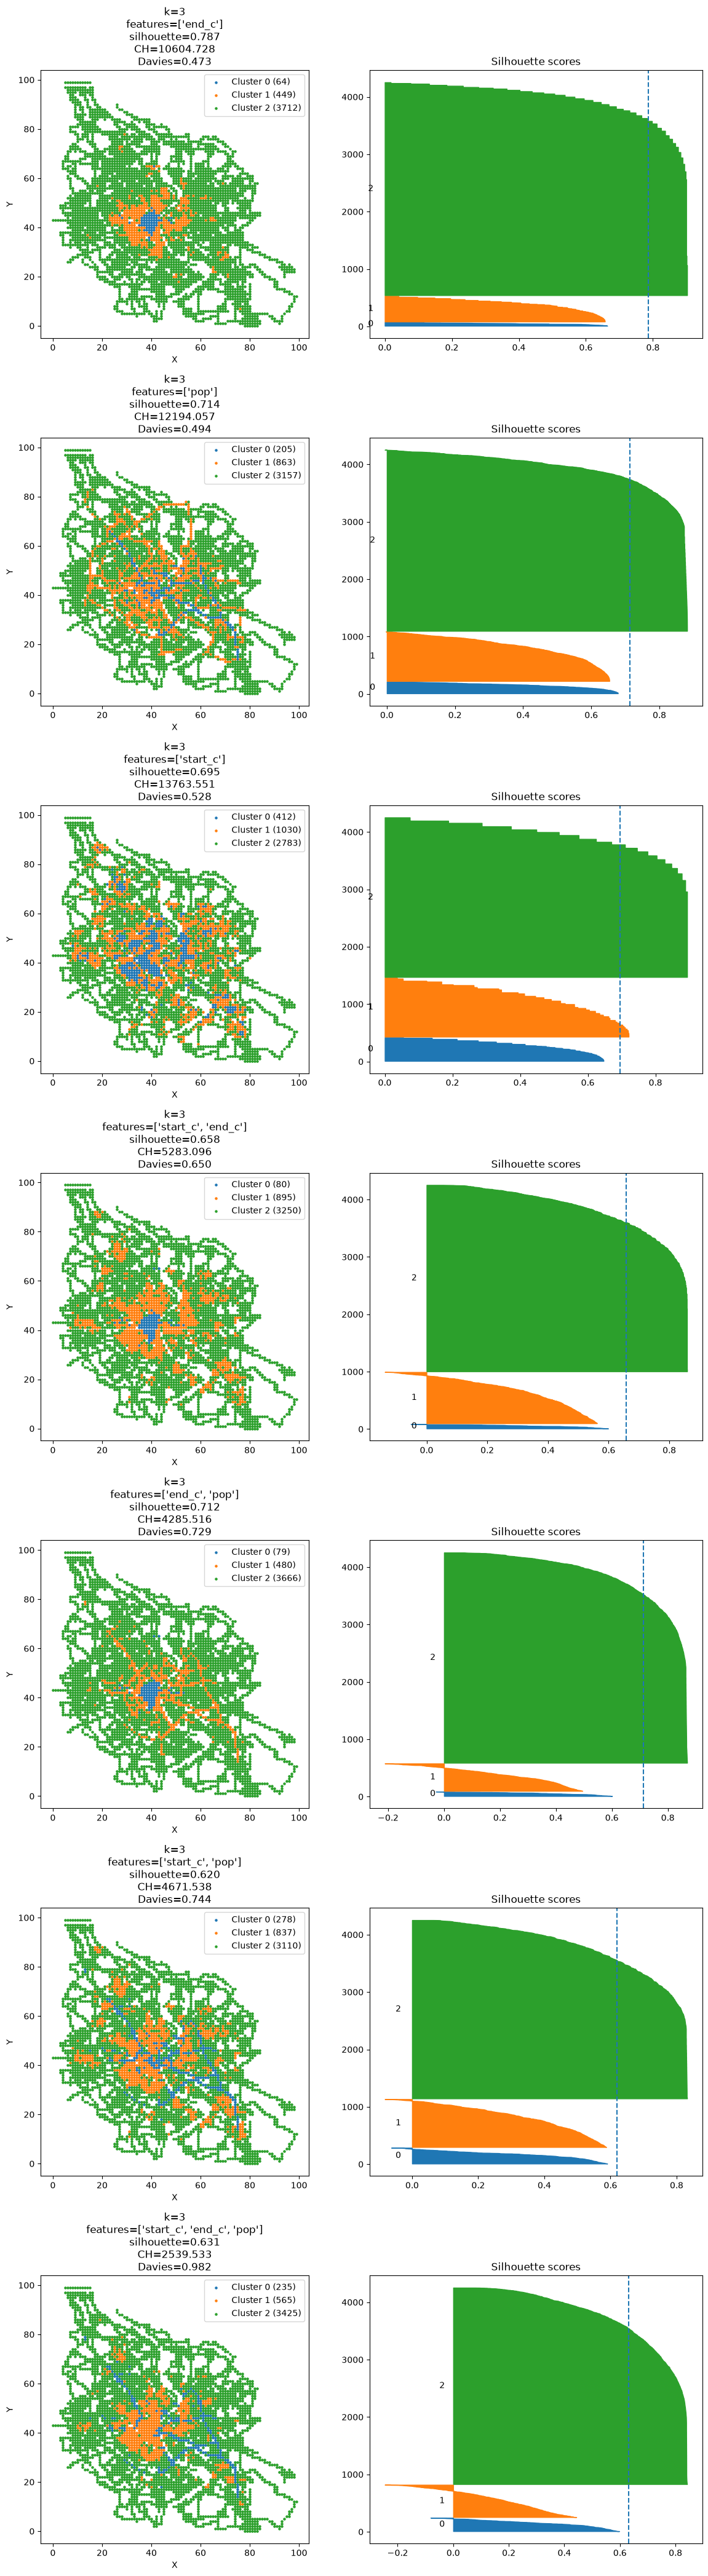

In [7]:
cluster_utils.Clustering.plot_celldf_best_kmeans_results_for_each_feature_combination_and_k(
    df=cell_df,
    features_combs=[
        ["end_c"],
        ["pop"],
        ["start_c"],
        ["start_c", "end_c"],
        ["end_c", "pop"],
        ["start_c", "pop"],
        ["start_c", "end_c", "pop"]
    ],
    ks=[
        3,
        3,
        3,
        3,
        3,
        3,
        3
    ],
    n_runs=30,
    figsize=(12, 42),
    nrows=7
)
plt.show()

## **5. Conclusions**

#### 1. Kmeans overall is not very good for clustering cells features (which convey the spatial structure of the mobility); maybe graph based modelling performs better; simulation scenario and mobility modelling are very important factors (not our problem/scope);

#### 2. It performs reasonably well for trivial features, notably **end_c** alone during morning and **start_c** alone during evening; **pop** always performs well, as it is the most trivial feature;

#### 3. Using more features tends to worsen results;

#### 4. For deployment purposes or service/mobility patterns detection, insights are not immediate by visualization; see **c_clust_kmeans_interp.ipynb**